<a href="https://colab.research.google.com/github/Ariqq16/ML_2026/blob/main/JS08/Tugas_Lab2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Langkah 1 - Import Library

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import HDBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score

iris = load_iris()

X = iris.data
y_asli = iris.target

df = pd.DataFrame(X, columns=iris.feature_names)
df['Spesies_Asli'] = [
    iris.target_names[i] for i in y_asli
]

print("Lima data pertama:")
display(df.head())

print("\nUkuran dataset:", X.shape)
print("Jumlah fitur:", len(iris.feature_names))
print("Jumlah sampel:", len(X))

print("\nDistribusi spesies asli:")
print(df['Spesies_Asli'].value_counts())

Lima data pertama:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Spesies_Asli
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa



Ukuran dataset: (150, 4)
Jumlah fitur: 4
Jumlah sampel: 150

Distribusi spesies asli:
Spesies_Asli
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


In [2]:
# Langkah 2 - Standardisasi data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Data sebelum standardisasi:")
print(X[:5])

print("\nData setelah standardisasi:")
print(np.round(X_scaled[:5], 3))

Data sebelum standardisasi:
[[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]
 [4.7 3.2 1.3 0.2]
 [4.6 3.1 1.5 0.2]
 [5.  3.6 1.4 0.2]]

Data setelah standardisasi:
[[-0.901  1.019 -1.34  -1.315]
 [-1.143 -0.132 -1.34  -1.315]
 [-1.385  0.328 -1.397 -1.315]
 [-1.507  0.098 -1.283 -1.315]
 [-1.022  1.249 -1.34  -1.315]]


In [3]:
# Langkah 3 - Membuat model HDBSCAN
model = HDBSCAN(
    min_cluster_size=5,
    min_samples=3
)

labels = model.fit_predict(X_scaled)

df['Cluster'] = labels

print("Hasil klasterisasi:")
display(df.head(10))

Hasil klasterisasi:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Spesies_Asli,Cluster
0,5.1,3.5,1.4,0.2,setosa,0
1,4.9,3.0,1.4,0.2,setosa,0
2,4.7,3.2,1.3,0.2,setosa,0
3,4.6,3.1,1.5,0.2,setosa,0
4,5.0,3.6,1.4,0.2,setosa,0
5,5.4,3.9,1.7,0.4,setosa,0
6,4.6,3.4,1.4,0.3,setosa,0
7,5.0,3.4,1.5,0.2,setosa,0
8,4.4,2.9,1.4,0.2,setosa,0
9,4.9,3.1,1.5,0.1,setosa,0


In [4]:
# Langkah 4 - Menghitung cluster dan noise
jumlah_cluster = len(set(labels) - {-1})
jumlah_noise = np.sum(labels == -1)

print("Jumlah cluster yang terbentuk:", jumlah_cluster)
print("Jumlah data noise:", jumlah_noise)

print("\nJumlah anggota setiap cluster:")
print(df['Cluster'].value_counts().sort_index())

Jumlah cluster yang terbentuk: 2
Jumlah data noise: 0

Jumlah anggota setiap cluster:
Cluster
0     50
1    100
Name: count, dtype: int64


In [5]:
# Langkah 5 - Reduksi dimensi menggunakan PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print(
    "Total variasi yang dijelaskan oleh dua komponen PCA:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

Total variasi yang dijelaskan oleh dua komponen PCA: 95.81 %


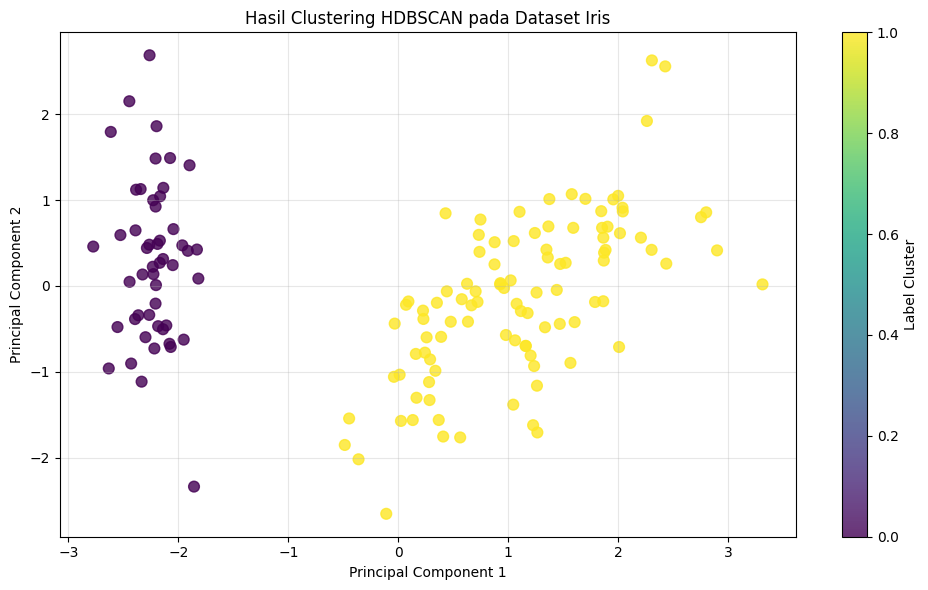

In [6]:
# Langkah 6 - Visualisasi hasil HDBSCAN
plt.figure(figsize=(10, 6))

scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=labels,
    cmap='viridis',
    s=60,
    alpha=0.8
)

plt.title('Hasil Clustering HDBSCAN pada Dataset Iris')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')

plt.colorbar(scatter, label='Label Cluster')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [7]:
# Langkah 7 - Membandingkan cluster dengan spesies asli
tabel_perbandingan = pd.crosstab(
    df['Spesies_Asli'],
    df['Cluster'],
    rownames=['Spesies Asli'],
    colnames=['Cluster HDBSCAN']
)

print("Tabel perbandingan spesies asli dan cluster:")
display(tabel_perbandingan)

Tabel perbandingan spesies asli dan cluster:


Cluster HDBSCAN,0,1
Spesies Asli,,
setosa,50,0
versicolor,0,50
virginica,0,50


In [8]:
# Langkah 8 - Evaluasi menggunakan ARI
ari = adjusted_rand_score(y_asli, labels)

print("Adjusted Rand Index (ARI):", round(ari, 4))

Adjusted Rand Index (ARI): 0.5681
